<a href="https://colab.research.google.com/github/PARZIVAL283/Customer_review_analysis/blob/main/customer_review_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Section 1

# Core libraries

In [1]:
!pip install pandas numpy matplotlib seaborn plotly kagglehub

importing libraries

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

# dataset form kaggle

In [3]:
import kagglehub

path = kagglehub.dataset_download(
    "promptcloud/amazon-product-reviews-dataset"
)

print("Downloaded dataset path:")
print(path)

csv_files = [
    file for file in os.listdir(path)
    if file.lower().endswith(".csv")
]

print("CSV files found:", csv_files)

df = pd.read_csv(os.path.join(path, csv_files[0]))

print(f"Dataset shape: {df.shape}")
df.head()

100%|██████████| 12.5k/12.5k [00:00<00:00, 15.1MB/s]

Extracting files...
Downloaded dataset path:
/root/.cache/kagglehub/datasets/promptcloud/amazon-product-reviews-dataset/versions/1
CSV files found: ['amazon_com-product_reviews__20200101_20200331_sample.csv']
Dataset shape: (50, 18)


,Uniq Id,Crawl Timestamp,Billing Uniq Id,Rating,Review Title,Review Rating,Review Date,User Id,Brand,Category,Sub Category,Product Description,Asin,Url,Review Content,Verified Purchase,Helpful Review Count,Manufacturer Response
0,10d8b81dc693db8a3f92e19254525d53,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Best Natural Deodorant!!,5.0,"March 6, 2020",AGIZFDSHLSBZ7KHQ4FV65W7B3HMQ,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innov...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R2Q...,This is the one natural deodorant that works f...,Verified Purchase,0,NaN
1,31ef1ee4961d3fcff33e363edd7677eb,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Schmidt's Charcoal Deodorant is the best!,5.0,"March 6, 2020",AHOZPYWO6WE5MLAZZPDUAWNKKNRQ,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innov...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R14...,I am staying away from the conventional deodor...,Verified Purchase,0,NaN
2,6943e517922b051cbec496be32fbb57f,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Beware. Defective or counterfeit.,1.0,"March 6, 2020",AECC6GYWWLNCKSBG3DZDGFSYDOTA,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innov...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R2R...,Do not buy this from Amazon it's either defect...,Verified Purchase,One person found this helpful Helpful,NaN
3,6778c794e6ac7112981d4ebb239d6826,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Good for infrequent shavers in cooler months i...,3.0,"March 5, 2020",AEOO6OOEO4QD7Z4F6C2FMZUCW7PA,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innov...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/RMI...,I started using this because I was getting cys...,NO,0,NaN
4,2335a28ae24db3b2191080bfd98a86e0,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,This isn’t the true product and will hurt your...,1.0,"March 2, 2020",AEHSDCGRIMVOUG6ST35FJ4FMMW5Q,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innov...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R1R...,Dont buy this from amazon!!!! I never write re...,Verified Purchase,One person found this helpful Helpful,NaN


# First inspection of dataset

In [4]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst five rows:")
df.head()

Shape: (50, 18)

Columns:
['Uniq Id', 'Crawl Timestamp', 'Billing Uniq Id', 'Rating', 'Review Title', 'Review Rating', 'Review Date', 'User Id', 'Brand', 'Category', 'Sub Category', 'Product Description', 'Asin', 'Url', 'Review Content', 'Verified Purchase', 'Helpful Review Count', 'Manufacturer Response']

Data types:
Uniq Id                   object
Crawl Timestamp           object
Billing Uniq Id           object
Rating                   float64
Review Title              object
Review Rating            float64
Review Date               object
User Id                   object
Brand                     object
Category                  object
Sub Category              object
Product Description       object
Asin                      object
Url                       object
Review Content            object
Verified Purchase         object
Helpful Review Count      object
Manufacturer Response    float64
dtype: object

First five rows:


,Uniq Id,Crawl Timestamp,Billing Uniq Id,Rating,Review Title,Review Rating,Review Date,User Id,Brand,Category,Sub Category,Product Description,Asin,Url,Review Content,Verified Purchase,Helpful Review Count,Manufacturer Response
0,10d8b81dc693db8a3f92e19254525d53,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Best Natural Deodorant!!,5.0,"March 6, 2020",AGIZFDSHLSBZ7KHQ4FV65W7B3HMQ,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innov...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R2Q...,This is the one natural deodorant that works f...,Verified Purchase,0,NaN
1,31ef1ee4961d3fcff33e363edd7677eb,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Schmidt's Charcoal Deodorant is the best!,5.0,"March 6, 2020",AHOZPYWO6WE5MLAZZPDUAWNKKNRQ,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innov...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R14...,I am staying away from the conventional deodor...,Verified Purchase,0,NaN
2,6943e517922b051cbec496be32fbb57f,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Beware. Defective or counterfeit.,1.0,"March 6, 2020",AECC6GYWWLNCKSBG3DZDGFSYDOTA,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innov...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R2R...,Do not buy this from Amazon it's either defect...,Verified Purchase,One person found this helpful Helpful,NaN
3,6778c794e6ac7112981d4ebb239d6826,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Good for infrequent shavers in cooler months i...,3.0,"March 5, 2020",AEOO6OOEO4QD7Z4F6C2FMZUCW7PA,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innov...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/RMI...,I started using this because I was getting cys...,NO,0,NaN
4,2335a28ae24db3b2191080bfd98a86e0,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,This isn’t the true product and will hurt your...,1.0,"March 2, 2020",AEHSDCGRIMVOUG6ST35FJ4FMMW5Q,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innov...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R1R...,Dont buy this from amazon!!!! I never write re...,Verified Purchase,One person found this helpful Helpful,NaN


checking missing values

In [5]:
missing_summary = df.isna().sum().sort_values(ascending=False)

missing_df = pd.DataFrame({
    "missing_count": missing_summary,
    "missing_percentage": (missing_summary / len(df) * 100).round(2)
})

missing_df

,missing_count,missing_percentage
Manufacturer Response,50,100.0
Rating,50,100.0
Product Description,1,2.0
Category,1,2.0
Sub Category,1,2.0
Uniq Id,0,0.0
Crawl Timestamp,0,0.0
Review Rating,0,0.0
Review Title,0,0.0
Billing Uniq Id,0,0.0


impact

In [6]:
text_columns = [
    col for col in df.columns
    if df[col].dtype == "object"
]

print("Potential text columns:", text_columns)

Potential text columns: ['Uniq Id', 'Crawl Timestamp', 'Billing Uniq Id', 'Review Title', 'Review Date', 'User Id', 'Brand', 'Category', 'Sub Category', 'Product Description', 'Asin', 'Url', 'Review Content', 'Verified Purchase', 'Helpful Review Count']


Duplicates

In [7]:
duplicate_rows = df.duplicated().sum()

print(f"Exact duplicate rows: {duplicate_rows}")

if "Review Title" in df.columns:
    duplicate_titles = df.duplicated(subset=["Review Title"]).sum()
    print(f"Duplicate review titles: {duplicate_titles}")

Exact duplicate rows: 0
Duplicate review titles: 1


# Understand ratings

Review Rating
1.0     6
2.0     2
3.0     3
4.0     5
5.0    34
Name: count, dtype: int64


/tmp/ipykernel_6064/3945352961.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=rating_column, palette="viridis")


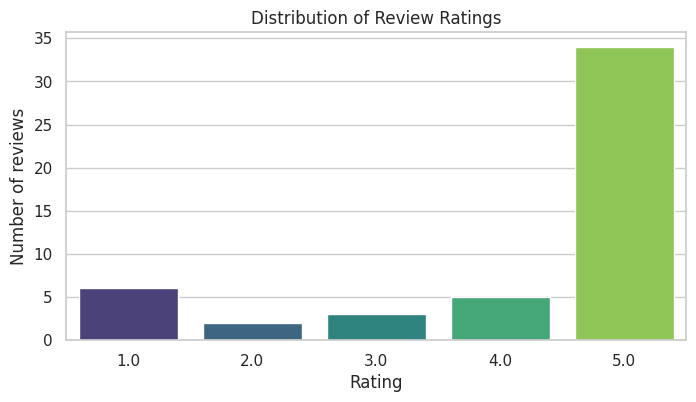

In [8]:
rating_column = "Review Rating"

if rating_column in df.columns:
    print(df[rating_column].value_counts().sort_index())

    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=rating_column, palette="viridis")
    plt.title("Distribution of Review Ratings")
    plt.xlabel("Rating")
    plt.ylabel("Number of reviews")
    plt.show()

# Understand categories

Unique categories: 2
Category
Beauty & Personal Care    36
Grocery & Gourmet Food    13
Name: count, dtype: int64


/tmp/ipykernel_6064/1369146796.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


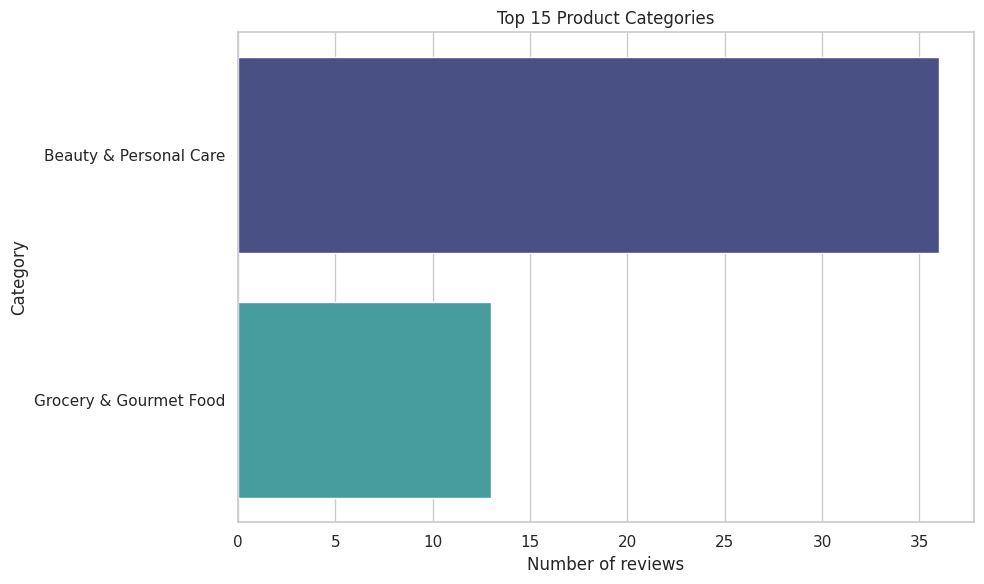

In [9]:
category_column = "Category"

if category_column in df.columns:
    print("Unique categories:", df[category_column].nunique())
    print(df[category_column].value_counts().head(20))

    plt.figure(figsize=(10, 6))
    top_categories = df[category_column].value_counts().head(15)

    sns.barplot(
        x=top_categories.values,
        y=top_categories.index,
        palette="mako"
    )

    plt.title("Top 15 Product Categories")
    plt.xlabel("Number of reviews")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.show()

# Understand dates

Valid dates: 50
Invalid dates: 0
Minimum date: 2017-09-04 00:00:00
Maximum date: 2020-03-13 00:00:00


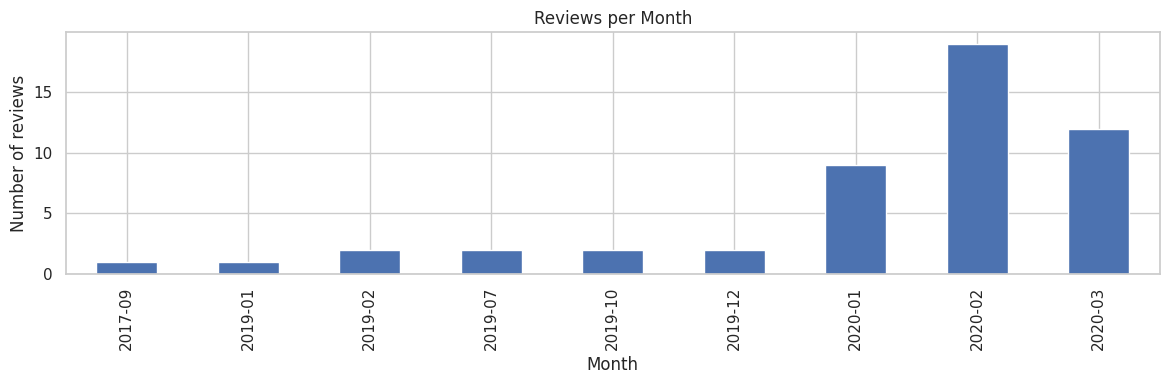

In [10]:
date_column = "Review Date"

if date_column in df.columns:
    df[date_column] = pd.to_datetime(
        df[date_column],
        errors="coerce"
    )

    print("Valid dates:", df[date_column].notna().sum())
    print("Invalid dates:", df[date_column].isna().sum())
    print("Minimum date:", df[date_column].min())
    print("Maximum date:", df[date_column].max())

    df[date_column].dt.to_period("M").value_counts().sort_index().plot(
        kind="bar",
        figsize=(12, 4),
        color="#4C72B0"
    )

    plt.title("Reviews per Month")
    plt.xlabel("Month")
    plt.ylabel("Number of reviews")
    plt.tight_layout()
    plt.show()

# Understand review length

count     50.000000
mean      32.820000
std       41.046857
min        1.000000
25%       10.500000
50%       20.500000
75%       39.000000
max      237.000000
Name: review_length_words, dtype: float64


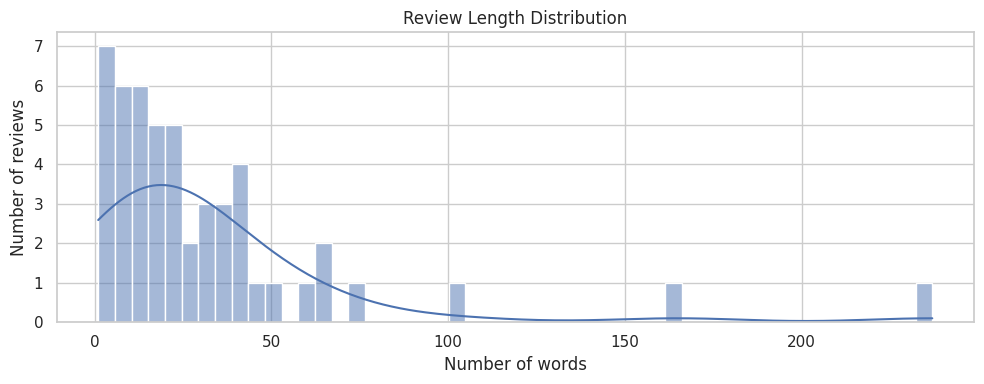

In [11]:
review_text_column = None

possible_text_columns = [

    "Review Content"
]

for column in possible_text_columns:
    if column in df.columns:
        review_text_column = column
        break

if review_text_column is None:
    print("Review text column not automatically detected.")
    print("Inspect df.columns and choose the correct column manually.")
else:
    df["review_length_words"] = (
        df[review_text_column]
        .astype(str)
        .str.split()
        .str.len()
    )

    print(df["review_length_words"].describe())

    plt.figure(figsize=(10, 4))
    sns.histplot(
        df["review_length_words"],
        bins=50,
        kde=True
    )

    plt.title("Review Length Distribution")
    plt.xlabel("Number of words")
    plt.ylabel("Number of reviews")
    plt.tight_layout()
    plt.show()

combining title and body for making working analysis column

In [12]:
title_column = "Review Title" if "Review Title" in df.columns else None
body_column = review_text_column

if title_column and body_column:
    df["raw_review_text"] = (
        df[title_column].fillna("").astype(str) + ". " +
        df[body_column].fillna("").astype(str)
    )
elif body_column:
    df["raw_review_text"] = df[body_column].fillna("").astype(str)
else:
    raise ValueError(
        "Could not identify a review text column. "
        "Please inspect df.columns and set review_text_column manually."
    )

df[["raw_review_text", "review_length_words"]].head()

,raw_review_text,review_length_words
0,Best Natural Deodorant!!. This is the one natu...,34
1,Schmidt's Charcoal Deodorant is the best!. I a...,101
2,Beware. Defective or counterfeit.. Do not buy ...,52
3,Good for infrequent shavers in cooler months i...,237
4,This isn’t the true product and will hurt your...,44


The review title often contains a concise opinion, such as “Excellent battery life” or “Terrible customer support.” The review body provides context. Combining them gives the sentiment and topic models more useful signal.

# Save the raw snapshot

In [13]:
os.makedirs("data", exist_ok=True)

df.to_csv("data/raw_reviews_stage1.csv", index=False)

print("Saved cleaned raw snapshot:")
print("data/raw_reviews_stage1.csv")
print("Rows:", len(df))

Saved cleaned raw snapshot:
data/raw_reviews_stage1.csv
Rows: 50


#Setion 2

In [14]:
!pip install nltk spacy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 18.5 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [15]:
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [16]:
import os
import re
import string
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

import spacy

pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")


Load the Stage 1 output

In [17]:
INPUT_PATH = "data/raw_reviews_stage1.csv"
OUTPUT_PATH = "data/preprocessed_reviews_stage2.csv"

df = pd.read_csv(INPUT_PATH)

print("Loaded dataset shape:", df.shape)
df.head(3)

Loaded dataset shape: (50, 20)


,Uniq Id,Crawl Timestamp,Billing Uniq Id,Rating,Review Title,Review Rating,Review Date,User Id,Brand,Category,Sub Category,Product Description,Asin,Url,Review Content,Verified Purchase,Helpful Review Count,Manufacturer Response,review_length_words,raw_review_text
0,10d8b81dc693db8a3f92e19254525d53,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Best Natural Deodorant!!,5.0,2020-03-06,AGIZFDSHLSBZ7KHQ4FV65W7B3HMQ,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innovative ingredients derived from plants and minerals to help effectively...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R2QDG3B3GJO8W/ref=cm_cr_arp_d_rvw_ttl?ie=UTF8&ASIN=B071YYMZ19,"This is the one natural deodorant that works for me, no b.o smell throughout the day! Score. Although it will never ...",Verified Purchase,0,NaN,34,"Best Natural Deodorant!!. This is the one natural deodorant that works for me, no b.o smell throughout the day! Scor..."
1,31ef1ee4961d3fcff33e363edd7677eb,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Schmidt's Charcoal Deodorant is the best!,5.0,2020-03-06,AHOZPYWO6WE5MLAZZPDUAWNKKNRQ,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innovative ingredients derived from plants and minerals to help effectively...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R14AFY08Z2YN9S/ref=cm_cr_arp_d_rvw_ttl?ie=UTF8&ASIN=B071YYMZ19,I am staying away from the conventional deodorants that have lots of fragrance combined with aluminum which is an ir...,Verified Purchase,0,NaN,101,Schmidt's Charcoal Deodorant is the best!. I am staying away from the conventional deodorants that have lots of frag...
2,6943e517922b051cbec496be32fbb57f,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Beware. Defective or counterfeit.,1.0,2020-03-06,AECC6GYWWLNCKSBG3DZDGFSYDOTA,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innovative ingredients derived from plants and minerals to help effectively...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R2RSQCFKI17X4L/ref=cm_cr_arp_d_rvw_ttl?ie=UTF8&ASIN=B071YYMZ19,"Do not buy this from Amazon it's either defective or counterfeit. I used to buy the same product at Costco, it works...",Verified Purchase,One person found this helpful Helpful,NaN,52,Beware. Defective or counterfeit.. Do not buy this from Amazon it's either defective or counterfeit. I used to buy t...


Create reusable functions

In [18]:
URL_PATTERN = re.compile(r"https?://\S+|www\.\S+")
HTML_TAG_PATTERN = re.compile(r"<.*?>")
NON_ALPHANUMERIC_PATTERN = re.compile(r"[^a-zA-Z\s]")
MULTIPLE_SPACES_PATTERN = re.compile(r"\s+")

STOP_WORDS = set(stopwords.words("english"))

# Keep negation words because they strongly affect sentiment.
NEGATION_WORDS = {
    "not", "no", "nor", "never", "n't", "cannot", "cant", "can't",
    "dont", "don't", "didnt", "didn't", "wont", "won't", "isnt",
    "isn't", "arent", "aren't", "wasnt", "wasn't", "werent", "weren't"
}

FINAL_STOP_WORDS = STOP_WORDS - NEGATION_WORDS

lemmatizer = WordNetLemmatizer()


def clean_text(text):
    """Clean a raw review while preserving useful sentiment words."""
    if pd.isna(text):
        return ""

    text = str(text).lower()

    # Remove URLs and HTML tags.
    text = URL_PATTERN.sub(" ", text)
    text = HTML_TAG_PATTERN.sub(" ", text)

    # Keep letters and spaces only.
    text = NON_ALPHANUMERIC_PATTERN.sub(" ", text)

    # Normalize repeated spaces.
    text = MULTIPLE_SPACES_PATTERN.sub(" ", text).strip()

    return text


def tokenize_text(text):
    """Convert cleaned text into individual words."""
    return word_tokenize(text)


def remove_stopwords(tokens):
    """Remove common non-informative words but retain negations."""
    return [
        token for token in tokens
        if token not in FINAL_STOP_WORDS
        and len(token) > 1
    ]


def lemmatize_tokens(tokens):
    """Reduce words to their base dictionary form."""
    return [lemmatizer.lemmatize(token) for token in tokens]


def preprocess_review(text):
    """Run the complete preprocessing pipeline for one review."""
    cleaned_text = clean_text(text)
    tokens = tokenize_text(cleaned_text)
    filtered_tokens = remove_stopwords(tokens)
    lemmatized_tokens = lemmatize_tokens(filtered_tokens)

    return " ".join(lemmatized_tokens)

# Apply preprocessing

In [19]:
df["clean_review_text"] = df["raw_review_text"].apply(clean_text)
df["preprocessed_review_text"] = df["raw_review_text"].apply(preprocess_review)

df["clean_word_count"] = df["clean_review_text"].str.split().str.len()
df["preprocessed_word_count"] = df["preprocessed_review_text"].str.split().str.len()

df[[
    "raw_review_text",
    "clean_review_text",
    "preprocessed_review_text",
    "clean_word_count",
    "preprocessed_word_count"
]].head(10)

,raw_review_text,clean_review_text,preprocessed_review_text,clean_word_count,preprocessed_word_count
0,"Best Natural Deodorant!!. This is the one natural deodorant that works for me, no b.o smell throughout the day! Scor...",best natural deodorant this is the one natural deodorant that works for me no b o smell throughout the day score alt...,best natural deodorant one natural deodorant work no smell throughout day score although never absorb quite like can...,38,23
1,Schmidt's Charcoal Deodorant is the best!. I am staying away from the conventional deodorants that have lots of frag...,schmidt s charcoal deodorant is the best i am staying away from the conventional deodorants that have lots of fragra...,schmidt charcoal deodorant best staying away conventional deodorant lot fragrance combined aluminum irritant skin ba...,111,51
2,Beware. Defective or counterfeit.. Do not buy this from Amazon it's either defective or counterfeit. I used to buy t...,beware defective or counterfeit do not buy this from amazon it s either defective or counterfeit i used to buy the s...,beware defective counterfeit not buy amazon either defective counterfeit used buy product costco work great picture ...,57,30
3,Good for infrequent shavers in cooler months in unimportant clothes. I started using this because I was getting cyst...,good for infrequent shavers in cooler months in unimportant clothes i started using this because i was getting cysts...,good infrequent shaver cooler month unimportant clothes started using getting cyst aluminum antiperspirant studying ...,247,130
4,This isn’t the true product and will hurt your armpits!. Dont buy this from amazon!!!! I never write reviews but fel...,this isn t the true product and will hurt your armpits dont buy this from amazon i never write reviews but felt othe...,true product hurt armpit dont buy amazon never write review felt others know using deodorant purchased time amazon r...,57,24
5,A good choice for deodorant. Great natural deodorant! It works!,a good choice for deodorant great natural deodorant it works,good choice deodorant great natural deodorant work,10,7
6,Nice Smell. Great for those who are sensitive to perfumed deorderants! Nice smell & works great!,nice smell great for those who are sensitive to perfumed deorderants nice smell works great,nice smell great sensitive perfumed deorderants nice smell work great,15,10
7,Works OK but stains clothes. Well I stopped using it today. Gave it about 3 weeks and honestly it wasn't bad smellin...,works ok but stains clothes well i stopped using it today gave it about weeks and honestly it wasn t bad smelling di...,work ok stain clothes well stopped using today gave week honestly bad smelling react terribly bc really need much ok...,72,41
8,My skin hated it. I was excited to try this deodorant. I have been wanting to find a good non-aluminum deodorant. I'...,my skin hated it i was excited to try this deodorant i have been wanting to find a good non aluminum deodorant i ve ...,skin hated excited try deodorant wanting find good non aluminum deodorant used dove year no problem read non aluminu...,176,81
9,"My go to. The only deodorant I’ll ever use anymore, no other similar brands compare! Long lasting, the only thing th...",my go to the only deodorant i ll ever use anymore no other similar brands compare long lasting the only thing that a...,go deodorant ever use anymore no similar brand compare long lasting thing actually stop odor,25,15


# Handle missing and short reviews

In [20]:
MINIMUM_WORDS = 3

df["is_valid_for_nlp"] = (
    df["preprocessed_review_text"].notna()
    & (df["preprocessed_word_count"] >= MINIMUM_WORDS)
)

print("Total reviews:", len(df))
print("Reviews valid for NLP:", df["is_valid_for_nlp"].sum())
print("Reviews excluded from topic modeling:", (~df["is_valid_for_nlp"]).sum())

df["is_valid_for_nlp"].value_counts()

Total reviews: 50
Reviews valid for NLP: 49
Reviews excluded from topic modeling: 1


,count
is_valid_for_nlp,
True,49
False,1


Inspect preprocessing quality

In [21]:
sample_reviews = df.loc[
    df["is_valid_for_nlp"],
    ["raw_review_text", "clean_review_text", "preprocessed_review_text"]
].sample(10, random_state=42)

sample_reviews


,raw_review_text,clean_review_text,preprocessed_review_text
13,"Just a tad different flavor.. First, this is a bit pricier than the usual store bought but I couldn't resist trying ...",just a tad different flavor first this is a bit pricier than the usual store bought but i couldn t resist trying it ...,tad different flavor first bit pricier usual store bought resist trying definitely different spice pop also not seem...
46,Perfect. I love this product.,perfect i love this product,perfect love product
48,A little goes a long way!. This is officially my favorite brand of oils. I have really dry skin and would run throug...,a little goes a long way this is officially my favorite brand of oils i have really dry skin and would run through o...,little go long way officially favorite brand oil really dry skin would run oil apply six time day brand use morning ...
45,Lavender wild orchid oil. SheaMoisture lavender wild orchid oil makes your skin feel so smooth .i also like the scen...,lavender wild orchid oil sheamoisture lavender wild orchid oil makes your skin feel so smooth i also like the scent ...,lavender wild orchid oil sheamoisture lavender wild orchid oil make skin feel smooth also like scent nice light
17,Too Scented. Very very Strong scent!!!!!i threw it away. I thought since it was supposed to be for sensitive people ...,too scented very very strong scent i threw it away i thought since it was supposed to be for sensitive people it wou...,scented strong scent threw away thought since supposed sensitive people scented
27,Great soap. I love eveything about this soap and it scans on the think dirty app at a 3 which is awesome,great soap i love eveything about this soap and it scans on the think dirty app at a which is awesome,great soap love eveything soap scan think dirty app awesome
26,"Wonderful soap!. The smell, size and lather are perfect.",wonderful soap the smell size and lather are perfect,wonderful soap smell size lather perfect
25,Just like it. Will buy again.. Love the scent and the feeling after every shower.,just like it will buy again love the scent and the feeling after every shower,like buy love scent feeling every shower
31,It will dried your skin a a lot. It will dried your skin a a lot,it will dried your skin a a lot it will dried your skin a a lot,dried skin lot dried skin lot
19,Back Up Mr Onion!. I love this stuff. I tried so many different products. Toms of Maine would not keep Mr onion away...,back up mr onion i love this stuff i tried so many different products toms of maine would not keep mr onion away thi...,back mr onion love stuff tried many different product tom maine would not keep mr onion away product yummy keep funk...


inspect the shortest valid reviews

In [22]:
shortest_valid_reviews = df.loc[
    df["is_valid_for_nlp"]
].sort_values("preprocessed_word_count").head(10)

shortest_valid_reviews[[
    "raw_review_text",
    "preprocessed_review_text",
    "preprocessed_word_count"
]]

,raw_review_text,preprocessed_review_text,preprocessed_word_count
11,Yummy!. Tastes great!,yummy taste great,3
29,Great for the skin. Soft,great skin soft,3
46,Perfect. I love this product.,perfect love product,3
38,"Delicious!. Very yummy, I love Talenti",delicious yummy love talenti,4
10,"Yum. Excellent mustard, I highly recommend",yum excellent mustard highly recommend,5
26,"Wonderful soap!. The smell, size and lather are perfect.",wonderful soap smell size lather perfect,6
31,It will dried your skin a a lot. It will dried your skin a a lot,dried skin lot dried skin lot,6
22,Perfect and unisex!. Me and my husband enjoyed the smell and the coverage!,perfect unisex husband enjoyed smell coverage,6
40,Fabulous. Fabulous fabulous fabulous I can’t get enough of this!!!,fabulous fabulous fabulous fabulous get enough,6
28,Moisturizer. I like the scent I use it to keep my skin healthy,moisturizer like scent use keep skin healthy,7


# Visualize review lengths

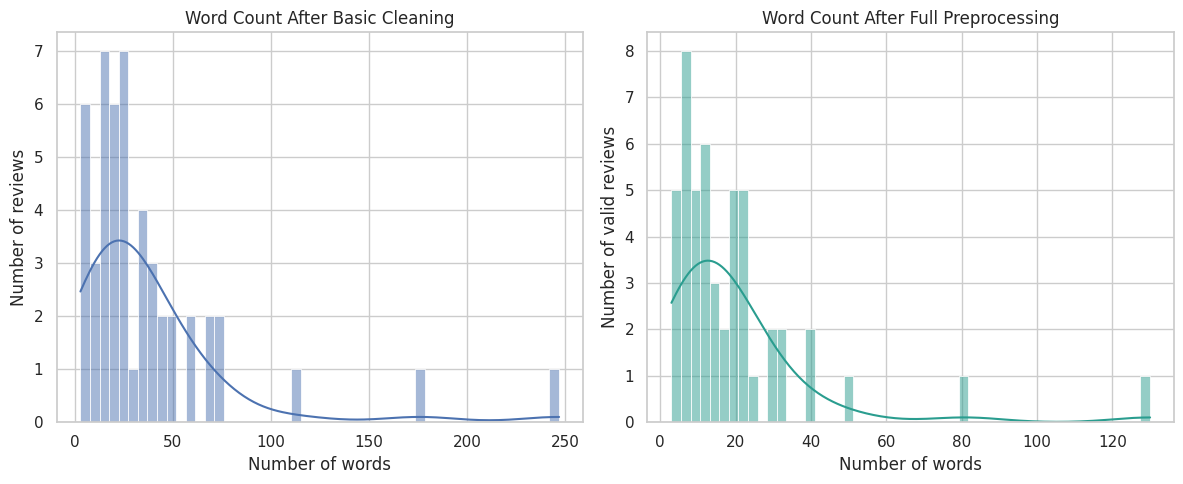

In [23]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df["clean_word_count"], bins=50, kde=True)
plt.title("Word Count After Basic Cleaning")
plt.xlabel("Number of words")
plt.ylabel("Number of reviews")

plt.subplot(1, 2, 2)
sns.histplot(
    df.loc[df["is_valid_for_nlp"], "preprocessed_word_count"],
    bins=50,
    kde=True,
    color="#2a9d8f"
)
plt.title("Word Count After Full Preprocessing")
plt.xlabel("Number of words")
plt.ylabel("Number of valid reviews")

plt.tight_layout()
plt.show()


# Find frequent words

/tmp/ipykernel_6064/643016431.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


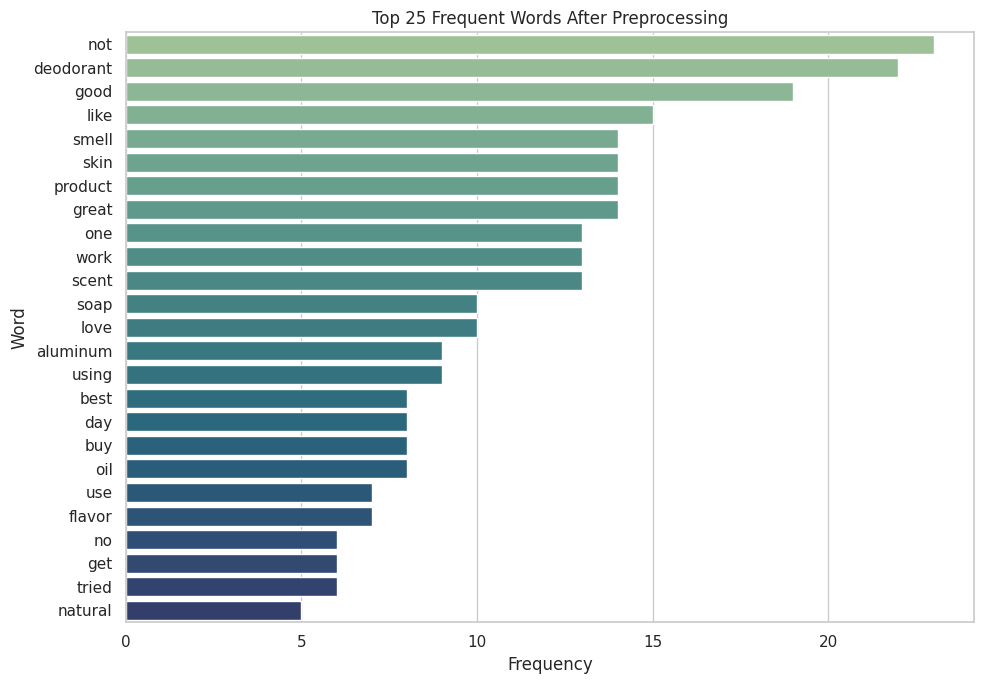

,word,frequency
0,not,23
1,deodorant,22
2,good,19
3,like,15
4,smell,14
5,skin,14
6,product,14
7,great,14
8,one,13
9,work,13


In [24]:
from collections import Counter

all_tokens = " ".join(
    df.loc[df["is_valid_for_nlp"], "preprocessed_review_text"]
).split()

word_counts = Counter(all_tokens)
common_words = pd.DataFrame(
    word_counts.most_common(25),
    columns=["word", "frequency"]
)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=common_words,
    x="frequency",
    y="word",
    palette="crest"
)
plt.title("Top 25 Frequent Words After Preprocessing")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

common_words

# spaCy lemmatization

In [25]:
import spacy

nlp = spacy.load(
    "en_core_web_sm",
    disable=["parser", "ner"]
)

def spacy_preprocess_review(text):
    """Preprocess one review using spaCy lemmatization."""
    cleaned_text = clean_text(text)

    if not cleaned_text:
        return ""

    doc = nlp(cleaned_text)

    tokens = [
        token.lemma_.lower()
        for token in doc
        if not token.is_stop
        and not token.is_punct
        and not token.is_space
        and len(token.text) > 1
        and token.lemma_.lower() not in NEGATION_WORDS
    ]

    return " ".join(tokens)

In [26]:
sample_size = 50

df_sample = df.sample(sample_size, random_state=42).copy()

df_sample["spacy_preprocessed_review_text"] = (
    df_sample["raw_review_text"]
    .apply(spacy_preprocess_review)
)

df_sample[[
    "raw_review_text",
    "preprocessed_review_text",
    "spacy_preprocessed_review_text"
]].head(10)

,raw_review_text,preprocessed_review_text,spacy_preprocessed_review_text
13,"Just a tad different flavor.. First, this is a bit pricier than the usual store bought but I couldn't resist trying ...",tad different flavor first bit pricier usual store bought resist trying definitely different spice pop also not seem...,tad different flavor bit pricy usual store buy couldn resist try definitely different spice pop separate easily usua...
39,Heavenly 😋. So delicious. I can only buy this every few months. So good I’ll eat it all at once,heavenly delicious buy every month good eat,heavenly delicious buy month good ll eat
30,This is my favorite soap. I use this soap for my sensitive skin. It’s moisturizing and smells great.,favorite soap use soap sensitive skin moisturizing smell great,favorite soap use soap sensitive skin moisturize smell great
45,Lavender wild orchid oil. SheaMoisture lavender wild orchid oil makes your skin feel so smooth .i also like the scen...,lavender wild orchid oil sheamoisture lavender wild orchid oil make skin feel smooth also like scent nice light,lavender wild orchid oil sheamoisture lavender wild orchid oil make skin feel smooth like scent nice light
17,Too Scented. Very very Strong scent!!!!!i threw it away. I thought since it was supposed to be for sensitive people ...,scented strong scent threw away thought since supposed sensitive people scented,scented strong scent throw away think suppose sensitive people wouldn scented
48,A little goes a long way!. This is officially my favorite brand of oils. I have really dry skin and would run throug...,little go long way officially favorite brand oil really dry skin would run oil apply six time day brand use morning ...,little go long way officially favorite brand oil dry skin run oil have apply time day brand use morning shower right...
26,"Wonderful soap!. The smell, size and lather are perfect.",wonderful soap smell size lather perfect,wonderful soap smell size lather perfect
25,Just like it. Will buy again.. Love the scent and the feeling after every shower.,like buy love scent feeling every shower,like buy love scent feeling shower
32,Good Product. I bought this soap for my daughter and daughter in law for Christmas and they both loved them. Said it...,good product bought soap daughter daughter law christmas loved said left skin soft not dry buy lot odor plus,good product buy soap daughter daughter law christmas love say leave skin soft dry buy doesn lot odor plus
19,Back Up Mr Onion!. I love this stuff. I tried so many different products. Toms of Maine would not keep Mr onion away...,back mr onion love stuff tried many different product tom maine would not keep mr onion away product yummy keep funk...,mr onion love stuff try different product tom maine mr onion away product yummy keep funk stay thick long redness arm


# Save Stage 2 output

In [27]:
os.makedirs("data", exist_ok=True)

df.to_csv(OUTPUT_PATH, index=False)

print("Saved preprocessed dataset:")
print(OUTPUT_PATH)
print("Final shape:", df.shape)
print("Valid reviews for NLP:", int(df["is_valid_for_nlp"].sum()))

Saved preprocessed dataset:
data/preprocessed_reviews_stage2.csv
Final shape: (50, 25)
Valid reviews for NLP: 49


# Section 3

In [28]:
!pip install nltk transformers torch accelerate

In [29]:
import nltk

nltk.download("vader_lexicon")

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


True

# Load Stage 2 data

In [30]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.sentiment import SentimentIntensityAnalyzer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

INPUT_PATH = "data/preprocessed_reviews_stage2.csv"
OUTPUT_PATH = "data/sentiment_reviews_stage3.csv"

df = pd.read_csv(INPUT_PATH)

print("Loaded dataset shape:", df.shape)
df.head(3)

Loaded dataset shape: (50, 25)


,Uniq Id,Crawl Timestamp,Billing Uniq Id,Rating,Review Title,Review Rating,Review Date,User Id,Brand,Category,Sub Category,Product Description,Asin,Url,Review Content,Verified Purchase,Helpful Review Count,Manufacturer Response,review_length_words,raw_review_text,clean_review_text,preprocessed_review_text,clean_word_count,preprocessed_word_count,is_valid_for_nlp
0,10d8b81dc693db8a3f92e19254525d53,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Best Natural Deodorant!!,5.0,2020-03-06,AGIZFDSHLSBZ7KHQ4FV65W7B3HMQ,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innovative ingredients derived from plants and minerals to help effectively...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R2QDG3B3GJO8W/ref=cm_cr_arp_d_rvw_ttl?ie=UTF8&ASIN=B071YYMZ19,"This is the one natural deodorant that works for me, no b.o smell throughout the day! Score. Although it will never ...",Verified Purchase,0,NaN,34,"Best Natural Deodorant!!. This is the one natural deodorant that works for me, no b.o smell throughout the day! Scor...",best natural deodorant this is the one natural deodorant that works for me no b o smell throughout the day score alt...,best natural deodorant one natural deodorant work no smell throughout day score although never absorb quite like can...,38,23,True
1,31ef1ee4961d3fcff33e363edd7677eb,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Schmidt's Charcoal Deodorant is the best!,5.0,2020-03-06,AHOZPYWO6WE5MLAZZPDUAWNKKNRQ,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innovative ingredients derived from plants and minerals to help effectively...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R14AFY08Z2YN9S/ref=cm_cr_arp_d_rvw_ttl?ie=UTF8&ASIN=B071YYMZ19,I am staying away from the conventional deodorants that have lots of fragrance combined with aluminum which is an ir...,Verified Purchase,0,NaN,101,Schmidt's Charcoal Deodorant is the best!. I am staying away from the conventional deodorants that have lots of frag...,schmidt s charcoal deodorant is the best i am staying away from the conventional deodorants that have lots of fragra...,schmidt charcoal deodorant best staying away conventional deodorant lot fragrance combined aluminum irritant skin ba...,111,51,True
2,6943e517922b051cbec496be32fbb57f,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Beware. Defective or counterfeit.,1.0,2020-03-06,AECC6GYWWLNCKSBG3DZDGFSYDOTA,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innovative ingredients derived from plants and minerals to help effectively...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R2RSQCFKI17X4L/ref=cm_cr_arp_d_rvw_ttl?ie=UTF8&ASIN=B071YYMZ19,"Do not buy this from Amazon it's either defective or counterfeit. I used to buy the same product at Costco, it works...",Verified Purchase,One person found this helpful Helpful,NaN,52,Beware. Defective or counterfeit.. Do not buy this from Amazon it's either defective or counterfeit. I used to buy t...,beware defective or counterfeit do not buy this from amazon it s either defective or counterfeit i used to buy the s...,beware defective counterfeit not buy amazon either defective counterfeit used buy product costco work great picture ...,57,30,True



# Define sentiment labels

In [31]:
SENTIMENT_LABELS = ["Negative", "Neutral", "Positive"]

In [32]:
def rating_to_sentiment(rating):
    """Convert a 1-5 rating into a weak sentiment label."""
    if pd.isna(rating):
        return np.nan

    rating = float(rating)

    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"


if "Review Rating" in df.columns:
    df["rating_sentiment"] = df["Review Rating"].apply(rating_to_sentiment)
else:
    df["rating_sentiment"] = np.nan

df["rating_sentiment"].value_counts(dropna=False)

,count
rating_sentiment,
Positive,39
Negative,8
Neutral,3


# VADER baseline


In [33]:
vader_analyzer = SentimentIntensityAnalyzer()


def get_vader_scores(text):
    """Return VADER sentiment scores for one review."""
    if pd.isna(text) or str(text).strip() == "":
        return {
            "neg": 0.0,
            "neu": 1.0,
            "pos": 0.0,
            "compound": 0.0
        }

    return vader_analyzer.polarity_scores(str(text))


vader_results = df["raw_review_text"].apply(get_vader_scores)

df["vader_negative_score"] = vader_results.apply(lambda x: x["neg"])
df["vader_neutral_score"] = vader_results.apply(lambda x: x["neu"])
df["vader_positive_score"] = vader_results.apply(lambda x: x["pos"])
df["vader_compound_score"] = vader_results.apply(lambda x: x["compound"])

Convert VADER’s compound score into three classes

In [34]:
def vader_compound_to_label(compound_score, neutral_threshold=0.05):
    """Convert a VADER compound score into a three-class sentiment label."""
    if compound_score >= neutral_threshold:
        return "Positive"
    elif compound_score <= -neutral_threshold:
        return "Negative"
    else:
        return "Neutral"


df["vader_sentiment"] = df["vader_compound_score"].apply(
    vader_compound_to_label
)

df["vader_sentiment"].value_counts()

,count
vader_sentiment,
Positive,46
Negative,3
Neutral,1


How VADER classification works:

| Compound score         | Predicted sentiment |
| ---------------------- | ------------------- |
| 0.05 or higher         | Positive            |
| Between -0.05 and 0.05 | Neutral             |
| -0.05 or lower         | Negative            |




Inspect VADER predictions

In [35]:
vader_examples = df[[
    "raw_review_text",
    "vader_compound_score",
    "vader_sentiment",
    "rating_sentiment"
]].sample(10, random_state=42)

vader_examples

,raw_review_text,vader_compound_score,vader_sentiment,rating_sentiment
13,"Just a tad different flavor.. First, this is a bit pricier than the usual store bought but I couldn't resist trying ...",0.7684,Positive,Positive
39,Heavenly 😋. So delicious. I can only buy this every few months. So good I’ll eat it all at once,0.9039,Positive,Positive
30,This is my favorite soap. I use this soap for my sensitive skin. It’s moisturizing and smells great.,0.7964,Positive,Positive
45,Lavender wild orchid oil. SheaMoisture lavender wild orchid oil makes your skin feel so smooth .i also like the scen...,0.6486,Positive,Positive
17,Too Scented. Very very Strong scent!!!!!i threw it away. I thought since it was supposed to be for sensitive people ...,0.7218,Positive,Negative
48,A little goes a long way!. This is officially my favorite brand of oils. I have really dry skin and would run throug...,0.9258,Positive,Positive
26,"Wonderful soap!. The smell, size and lather are perfect.",0.8268,Positive,Positive
25,Just like it. Will buy again.. Love the scent and the feeling after every shower.,0.8020,Positive,Positive
32,Good Product. I bought this soap for my daughter and daughter in law for Christmas and they both loved them. Said it...,0.7783,Positive,Positive
19,Back Up Mr Onion!. I love this stuff. I tried so many different products. Toms of Maine would not keep Mr onion away...,0.8209,Positive,Positive


inspect disagreements

In [36]:
vader_disagreements = df.loc[
    df["rating_sentiment"].notna()
    & (df["vader_sentiment"] != df["rating_sentiment"]),
    [
        "raw_review_text",
        "Review Rating",
        "rating_sentiment",
        "vader_compound_score",
        "vader_sentiment"
    ]
].sample(10, random_state=42)

vader_disagreements

,raw_review_text,Review Rating,rating_sentiment,vader_compound_score,vader_sentiment
9,"My go to. The only deodorant I’ll ever use anymore, no other similar brands compare! Long lasting, the only thing th...",5.0,Positive,-0.4753,Negative
2,Beware. Defective or counterfeit.. Do not buy this from Amazon it's either defective or counterfeit. I used to buy t...,1.0,Negative,0.3818,Positive
36,Unless you're superman u cant open the lid. IMPOSSIBLE TO OPEN!! would have been nice to try it.,1.0,Negative,0.5242,Positive
41,Not For Me At All.. One thing I've learned after trying (8) different flavors of Talenti Gelato is that any one flav...,3.0,Neutral,0.9212,Positive
4,This isn’t the true product and will hurt your armpits!. Dont buy this from amazon!!!! I never write reviews but fel...,1.0,Negative,0.4438,Positive
3,Good for infrequent shavers in cooler months in unimportant clothes. I started using this because I was getting cyst...,3.0,Neutral,0.9470,Positive
31,It will dried your skin a a lot. It will dried your skin a a lot,1.0,Negative,0.0000,Neutral
8,My skin hated it. I was excited to try this deodorant. I have been wanting to find a good non-aluminum deodorant. I'...,3.0,Neutral,-0.7809,Negative
18,"Smells like ""3 for .99c"" soap, literally. Not sure what Bieber was on when he approved this. It has the smell of che...",2.0,Negative,0.5168,Positive
7,Works OK but stains clothes. Well I stopped using it today. Gave it about 3 weeks and honestly it wasn't bad smellin...,2.0,Negative,0.6818,Positive


# Visualize VADER results

/tmp/ipykernel_6064/2343180435.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


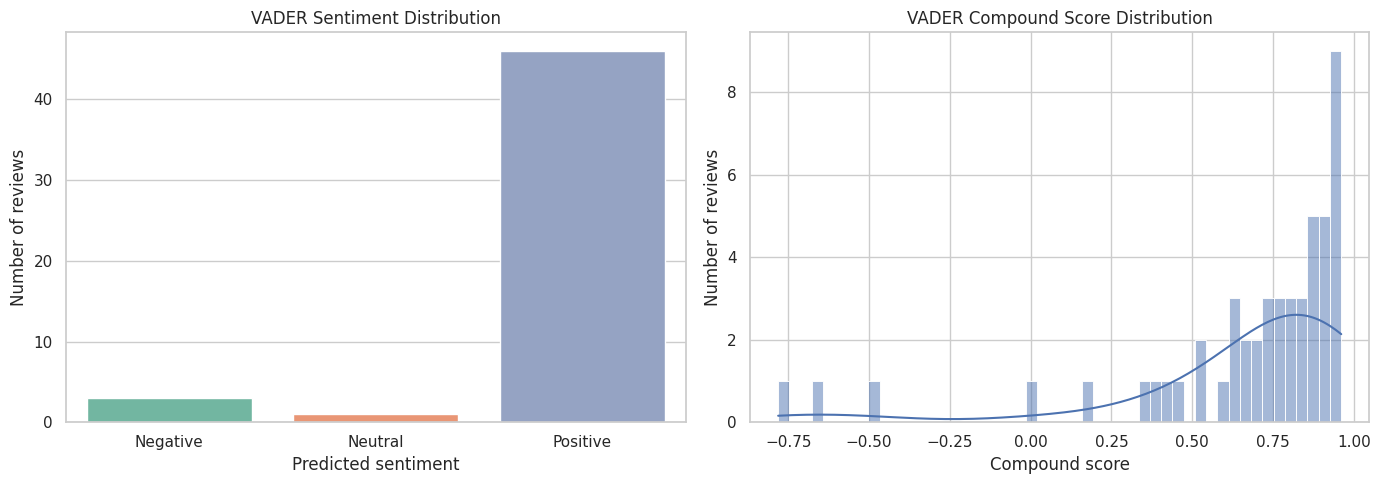

In [37]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.countplot(
    data=df,
    x="vader_sentiment",
    order=SENTIMENT_LABELS,
    palette="Set2"
)
plt.title("VADER Sentiment Distribution")
plt.xlabel("Predicted sentiment")
plt.ylabel("Number of reviews")

plt.subplot(1, 2, 2)
sns.histplot(
    data=df,
    x="vader_compound_score",
    bins=50,
    kde=True,
    color="#4C72B0"
)
plt.title("VADER Compound Score Distribution")
plt.xlabel("Compound score")
plt.ylabel("Number of reviews")

plt.tight_layout()
plt.show()

# Transformer sentiment model

In [39]:
from transformers import pipeline

TRANSFORMER_MODEL = (
    "cardiffnlp/twitter-roberta-base-sentiment-latest"
)

transformer_classifier = pipeline(
    task="sentiment-analysis",
    model=TRANSFORMER_MODEL,
    truncation=True,
    max_length=256,
    device=-1  # Use GPU in Colab. Change to -1 for CPU.
)

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Run Transformer predictions

In [40]:
from tqdm.auto import tqdm

tqdm.pandas()


def get_transformer_sentiment(text):
    """Classify one review using a Transformer sentiment model."""
    if pd.isna(text) or str(text).strip() == "":
        return pd.Series({
            "transformer_sentiment": "Neutral",
            "transformer_confidence": 0.0
        })

    result = transformer_classifier(str(text)[:512])[0]

    label = result["label"].lower()

    # Normalize labels across possible model outputs.
    if label in ["positive", "pos", "label_2"]:
        predicted_label = "Positive"
    elif label in ["negative", "neg", "label_0"]:
        predicted_label = "Negative"
    else:
        predicted_label = "Neutral"

    return pd.Series({
        "transformer_sentiment": predicted_label,
        "transformer_confidence": result["score"]
    })


transformer_results = df["raw_review_text"].progress_apply(
    get_transformer_sentiment
)

df["transformer_sentiment"] = transformer_results["transformer_sentiment"]
df["transformer_confidence"] = transformer_results["transformer_confidence"]

df["transformer_sentiment"].value_counts()

  0%|          | 0/50 [00:00<?, ?it/s]

,count
transformer_sentiment,
Positive,37
Negative,10
Neutral,3


# Compare VADER and Transformer

In [41]:
comparison_table = pd.crosstab(
    df["vader_sentiment"],
    df["transformer_sentiment"],
    rownames=["VADER prediction"],
    colnames=["Transformer prediction"]
)

comparison_table

Transformer prediction,Negative,Neutral,Positive
VADER prediction,,,
Negative,2,0,1
Neutral,0,1,0
Positive,8,2,36


# Evaluate against rating labels

In [42]:
evaluation_df = df.loc[
    df["rating_sentiment"].notna()
    & df["vader_sentiment"].notna()
    & df["transformer_sentiment"].notna()
].copy()

y_true = evaluation_df["rating_sentiment"]
vader_predictions = evaluation_df["vader_sentiment"]
transformer_predictions = evaluation_df["transformer_sentiment"]


def evaluate_sentiment_model(y_true, y_pred, model_name):
    """Calculate standard classification metrics."""
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Weighted Precision": precision,
        "Weighted Recall": recall,
        "Weighted F1-score": f1
    }


vader_metrics = evaluate_sentiment_model(
    y_true,
    vader_predictions,
    "VADER"
)

transformer_metrics = evaluate_sentiment_model(
    y_true,
    transformer_predictions,
    "Transformer"
)

metrics_df = pd.DataFrame([
    vader_metrics,
    transformer_metrics
]).round(4)

metrics_df

,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1-score
0,VADER,0.78,0.6977,0.78,0.7265
1,Transformer,0.84,0.8549,0.84,0.8456


# Detailed classification reports

In [43]:
print("VADER classification report:")
print(
    classification_report(
        y_true,
        vader_predictions,
        labels=SENTIMENT_LABELS,
        zero_division=0
    )
)

print("\nTransformer classification report:")
print(
    classification_report(
        y_true,
        transformer_predictions,
        labels=SENTIMENT_LABELS,
        zero_division=0
    )
)

VADER classification report:
              precision    recall  f1-score   support

    Negative       0.33      0.12      0.18         8
     Neutral       0.00      0.00      0.00         3
    Positive       0.83      0.97      0.89        39

    accuracy                           0.78        50
   macro avg       0.39      0.37      0.36        50
weighted avg       0.70      0.78      0.73        50


Transformer classification report:
              precision    recall  f1-score   support

    Negative       0.60      0.75      0.67         8
     Neutral       0.00      0.00      0.00         3
    Positive       0.97      0.92      0.95        39

    accuracy                           0.84        50
   macro avg       0.52      0.56      0.54        50
weighted avg       0.85      0.84      0.85        50



# Confusion matrices

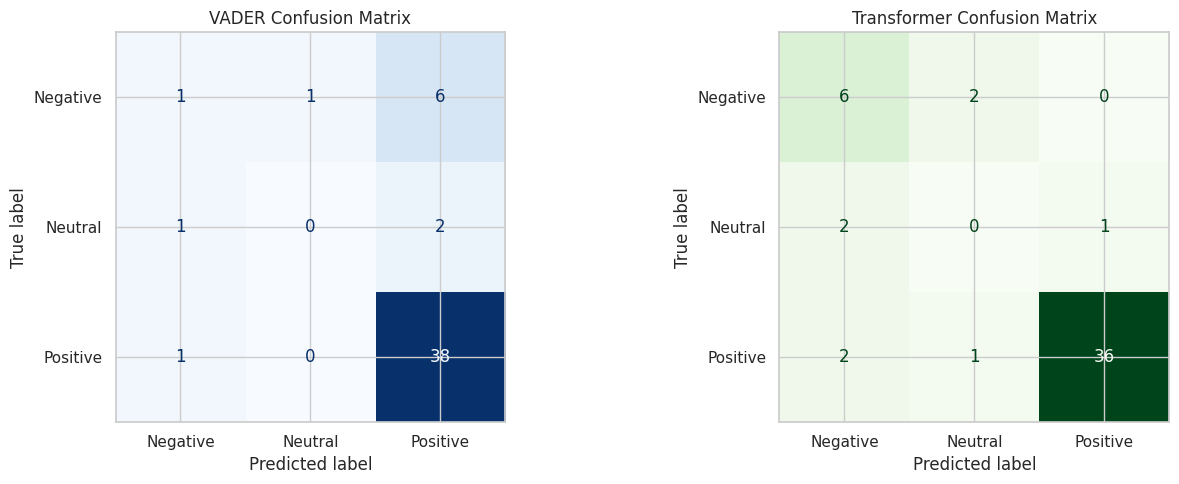

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay(
    confusion_matrix(
        y_true,
        vader_predictions,
        labels=SENTIMENT_LABELS
    ),
    display_labels=SENTIMENT_LABELS
).plot(ax=axes[0], colorbar=False, cmap="Blues")

axes[0].set_title("VADER Confusion Matrix")

ConfusionMatrixDisplay(
    confusion_matrix(
        y_true,
        transformer_predictions,
        labels=SENTIMENT_LABELS
    ),
    display_labels=SENTIMENT_LABELS
).plot(ax=axes[1], colorbar=False, cmap="Greens")

axes[1].set_title("Transformer Confusion Matrix")

plt.tight_layout()
plt.show()

# Sentiment by category

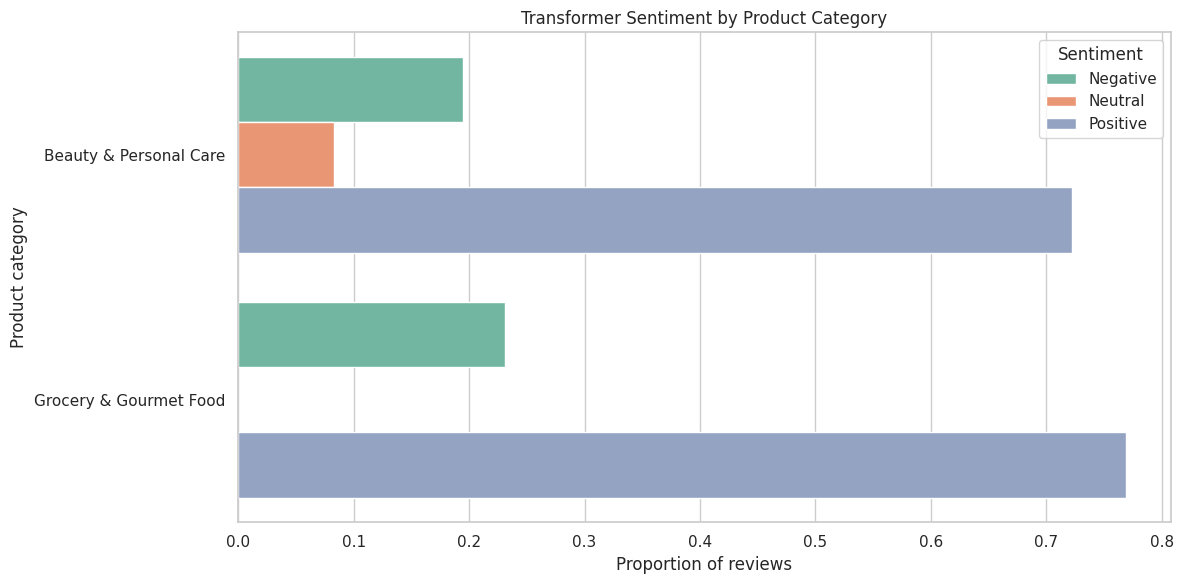

In [45]:
category_column = "Category"

if category_column in df.columns:
    category_sentiment = (
        df.groupby(category_column)["transformer_sentiment"]
        .value_counts(normalize=True)
        .rename("proportion")
        .reset_index()
    )

    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=category_sentiment,
        x="proportion",
        y=category_column,
        hue="transformer_sentiment",
        hue_order=SENTIMENT_LABELS,
        palette="Set2"
    )
    plt.title("Transformer Sentiment by Product Category")
    plt.xlabel("Proportion of reviews")
    plt.ylabel("Product category")
    plt.legend(title="Sentiment")
    plt.tight_layout()
    plt.show()

Save Stage 3 output

In [47]:
os.makedirs("data", exist_ok=True)

df.to_csv(OUTPUT_PATH, index=False)

print("Saved sentiment-analysis dataset:")
print(OUTPUT_PATH)
print("Final shape:", df.shape)

print("\nSentiment columns:")
print([
    "rating_sentiment",
    "vader_compound_score",
    "vader_sentiment",
    "transformer_sentiment",
    "transformer_confidence"
])

Saved sentiment-analysis dataset:
data/sentiment_reviews_stage3.csv
Final shape: (50, 33)

Sentiment columns:
['rating_sentiment', 'vader_compound_score', 'vader_sentiment', 'transformer_sentiment', 'transformer_confidence']


## Section 4


In [52]:
!pip install gensim bertopic sentence-transformers umap-learn hdbscan plotly

In [53]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

import gensim
from gensim import corpora
from gensim.models import CoherenceModel

from bertopic import BERTopic

pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

In [54]:
INPUT_PATH = "data/sentiment_reviews_stage3.csv"
OUTPUT_PATH = "data/topic_reviews_stage4.csv"

df = pd.read_csv(INPUT_PATH)

print("Loaded dataset shape:", df.shape)
df.head(3)

Loaded dataset shape: (50, 33)


,Uniq Id,Crawl Timestamp,Billing Uniq Id,Rating,Review Title,Review Rating,Review Date,User Id,Brand,Category,Sub Category,Product Description,Asin,Url,Review Content,Verified Purchase,Helpful Review Count,Manufacturer Response,review_length_words,raw_review_text,clean_review_text,preprocessed_review_text,clean_word_count,preprocessed_word_count,is_valid_for_nlp,rating_sentiment,vader_negative_score,vader_neutral_score,vader_positive_score,vader_compound_score,vader_sentiment,transformer_sentiment,transformer_confidence
0,10d8b81dc693db8a3f92e19254525d53,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Best Natural Deodorant!!,5.0,2020-03-06,AGIZFDSHLSBZ7KHQ4FV65W7B3HMQ,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innovative ingredients derived from plants and minerals to help effectively...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R2QDG3B3GJO8W/ref=cm_cr_arp_d_rvw_ttl?ie=UTF8&ASIN=B071YYMZ19,"This is the one natural deodorant that works for me, no b.o smell throughout the day! Score. Although it will never ...",Verified Purchase,0,NaN,34,"Best Natural Deodorant!!. This is the one natural deodorant that works for me, no b.o smell throughout the day! Scor...",best natural deodorant this is the one natural deodorant that works for me no b o smell throughout the day score alt...,best natural deodorant one natural deodorant work no smell throughout day score although never absorb quite like can...,38,23,True,Positive,0.179,0.566,0.255,0.5964,Positive,Positive,0.960582
1,31ef1ee4961d3fcff33e363edd7677eb,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Schmidt's Charcoal Deodorant is the best!,5.0,2020-03-06,AHOZPYWO6WE5MLAZZPDUAWNKKNRQ,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innovative ingredients derived from plants and minerals to help effectively...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R14AFY08Z2YN9S/ref=cm_cr_arp_d_rvw_ttl?ie=UTF8&ASIN=B071YYMZ19,I am staying away from the conventional deodorants that have lots of fragrance combined with aluminum which is an ir...,Verified Purchase,0,NaN,101,Schmidt's Charcoal Deodorant is the best!. I am staying away from the conventional deodorants that have lots of frag...,schmidt s charcoal deodorant is the best i am staying away from the conventional deodorants that have lots of fragra...,schmidt charcoal deodorant best staying away conventional deodorant lot fragrance combined aluminum irritant skin ba...,111,51,True,Positive,0.074,0.748,0.178,0.8872,Positive,Positive,0.859548
2,6943e517922b051cbec496be32fbb57f,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Beware. Defective or counterfeit.,1.0,2020-03-06,AECC6GYWWLNCKSBG3DZDGFSYDOTA,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innovative ingredients derived from plants and minerals to help effectively...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R2RSQCFKI17X4L/ref=cm_cr_arp_d_rvw_ttl?ie=UTF8&ASIN=B071YYMZ19,"Do not buy this from Amazon it's either defective or counterfeit. I used to buy the same product at Costco, it works...",Verified Purchase,One person found this helpful Helpful,NaN,52,Beware. Defective or counterfeit.. Do not buy this from Amazon it's either defective or counterfeit. I used to buy t...,beware defective or counterfeit do not buy this from amazon it s either defective or counterfeit i used to buy the s...,beware defective counterfeit not buy amazon either defective counterfeit used buy product costco work great picture ...,57,30,True,Negative,0.124,0.729,0.147,0.3818,Positive,Negative,0.609963


In [55]:
topic_df = df.loc[
    df["is_valid_for_nlp"] == True,
    [
        "raw_review_text",
        "preprocessed_review_text",
        "transformer_sentiment",
        "vader_sentiment",
        "rating_sentiment"
    ]
].copy().reset_index(drop=True)

print("Reviews used for topic modeling:", len(topic_df))
topic_df.head()

Reviews used for topic modeling: 49


,raw_review_text,preprocessed_review_text,transformer_sentiment,vader_sentiment,rating_sentiment
0,"Best Natural Deodorant!!. This is the one natural deodorant that works for me, no b.o smell throughout the day! Scor...",best natural deodorant one natural deodorant work no smell throughout day score although never absorb quite like can...,Positive,Positive,Positive
1,Schmidt's Charcoal Deodorant is the best!. I am staying away from the conventional deodorants that have lots of frag...,schmidt charcoal deodorant best staying away conventional deodorant lot fragrance combined aluminum irritant skin ba...,Positive,Positive,Positive
2,Beware. Defective or counterfeit.. Do not buy this from Amazon it's either defective or counterfeit. I used to buy t...,beware defective counterfeit not buy amazon either defective counterfeit used buy product costco work great picture ...,Negative,Positive,Negative
3,Good for infrequent shavers in cooler months in unimportant clothes. I started using this because I was getting cyst...,good infrequent shaver cooler month unimportant clothes started using getting cyst aluminum antiperspirant studying ...,Positive,Positive,Neutral
4,This isn’t the true product and will hurt your armpits!. Dont buy this from amazon!!!! I never write reviews but fel...,true product hurt armpit dont buy amazon never write review felt others know using deodorant purchased time amazon r...,Negative,Positive,Negative


# LDA topic model

In [56]:
MAX_FEATURES = 5000
MIN_DOCUMENT_FREQUENCY = 5
MAX_DOCUMENT_FREQUENCY = 0.50
NUMBER_OF_TOPICS = 8
TOP_WORDS_PER_TOPIC = 12
RANDOM_STATE = 42

vectorizer = CountVectorizer(
    max_features=MAX_FEATURES,
    min_df=MIN_DOCUMENT_FREQUENCY,
    max_df=MAX_DOCUMENT_FREQUENCY,
    ngram_range=(1, 2),
    stop_words="english"
)

doc_term_matrix = vectorizer.fit_transform(
    topic_df["preprocessed_review_text"]
)

print("Document-term matrix shape:", doc_term_matrix.shape)

Document-term matrix shape: (49, 18)


# Train the LDA model

In [57]:
lda_model = LatentDirichletAllocation(
    n_components=NUMBER_OF_TOPICS,
    max_iter=15,
    learning_method="online",
    learning_offset=50.0,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

lda_topic_matrix = lda_model.fit_transform(doc_term_matrix)

topic_df["lda_topic_id"] = lda_topic_matrix.argmax(axis=1)
topic_df["lda_topic_probability"] = lda_topic_matrix.max(axis=1)

print("LDA topic distribution:")
topic_df["lda_topic_id"].value_counts().sort_index()

LDA topic distribution:


,count
lda_topic_id,
0,11
1,1
2,5
4,8
6,3
7,21


# Inspect LDA topics

In [58]:
feature_names = vectorizer.get_feature_names_out()


def display_lda_topics(model, feature_names, top_words=12):
    """Print the most important words for each LDA topic."""
    for topic_index, topic_weights in enumerate(model.components_):
        top_word_indices = topic_weights.argsort()[::-1][:top_words]
        topic_words = [feature_names[index] for index in top_word_indices]

        print(f"Topic {topic_index}:")
        print(", ".join(topic_words))
        print("-" * 80)


display_lda_topics(
    lda_model,
    feature_names,
    top_words=TOP_WORDS_PER_TOPIC
)

Topic 0:
smell, soap, great, skin, sensitive, work, like, use, good, best, product, using
--------------------------------------------------------------------------------
Topic 1:
skin, like, scent, using, work, day, use, smell, great, love, best, product
--------------------------------------------------------------------------------
Topic 2:
scent, like, soap, great, love, using, sensitive, product, good, work, deodorant, smell
--------------------------------------------------------------------------------
Topic 3:
use, scent, skin, buy, deodorant, work, good, great, sensitive, best, tried, like
--------------------------------------------------------------------------------
Topic 4:
scent, love, like, smell, skin, use, day, buy, using, deodorant, best, work
--------------------------------------------------------------------------------
Topic 5:
like, scent, work, love, buy, tried, best, sensitive, deodorant, skin, use, good
---------------------------------------------------------

# Create human-readable topic labels

In [59]:
lda_topic_labels = {
    0: "Topic 0",
    1: "Topic 1",
    2: "Topic 2",
    3: "Topic 3",
    4: "Topic 4",
    5: "Topic 5",
    6: "Topic 6",
    7: "Topic 7"
}

topic_df["lda_topic_label"] = topic_df["lda_topic_id"].map(
    lda_topic_labels
)

topic_df["lda_topic_label"].value_counts()

,count
lda_topic_label,
Topic 7,21
Topic 0,11
Topic 4,8
Topic 2,5
Topic 6,3
Topic 1,1


In [60]:
lda_topic_labels = {
    0: "Battery and charging",
    1: "Delivery and shipping",
    2: "Product quality",
    3: "Price and value",
    4: "Customer service",
    5: "Packaging",
    6: "Product durability",
    7: "General experience"
}

topic_df["lda_topic_label"] = topic_df["lda_topic_id"].map(
    lda_topic_labels
)

In [61]:
def show_representative_reviews(
    dataframe,
    topic_column,
    text_column,
    number_of_reviews=3
):
    """Show the highest-confidence review for each topic."""
    for topic_id in sorted(dataframe[topic_column].unique()):
        topic_reviews = dataframe.loc[
            dataframe[topic_column] == topic_id
        ].sort_values(
            "lda_topic_probability",
            ascending=False
        ).head(number_of_reviews)

        print(f"\nTopic {topic_id}:")
        for review in topic_reviews[text_column]:
            print("-", review[:250].replace("\n", " "))


show_representative_reviews(
    topic_df,
    "lda_topic_id",
    "raw_review_text"
)


Topic 0:
- This is my favorite soap. I use this soap for my sensitive skin. It’s moisturizing and smells great.
- Nice Smell. Great for those who are sensitive to perfumed deorderants! Nice smell & works great!
- Smells like "3 for .99c" soap, literally. Not sure what Bieber was on when he approved this. It has the smell of cheap soap.

Topic 1:
- It will dried your skin a a lot. It will dried your skin a a lot

Topic 2:
- Great value. Really like this soap so far. Been using it for a week now. Great scent and moisturizing. Also like that it's a big bar of soap. Last longer for the money. Overall very pleased.
- The combined oils and scents are perfect!. I absolutely love this body oil! The combined oils and scents used are perfect. I like that it is a natural, organic, fair trade, and family product!
- Great soap. I love eveything about this soap and it scans on the think dirty app at a 3 which is awesome

Topic 4:
- Love the scent. I love this oil. I use it after my shower, before I

# LDA topic visualization

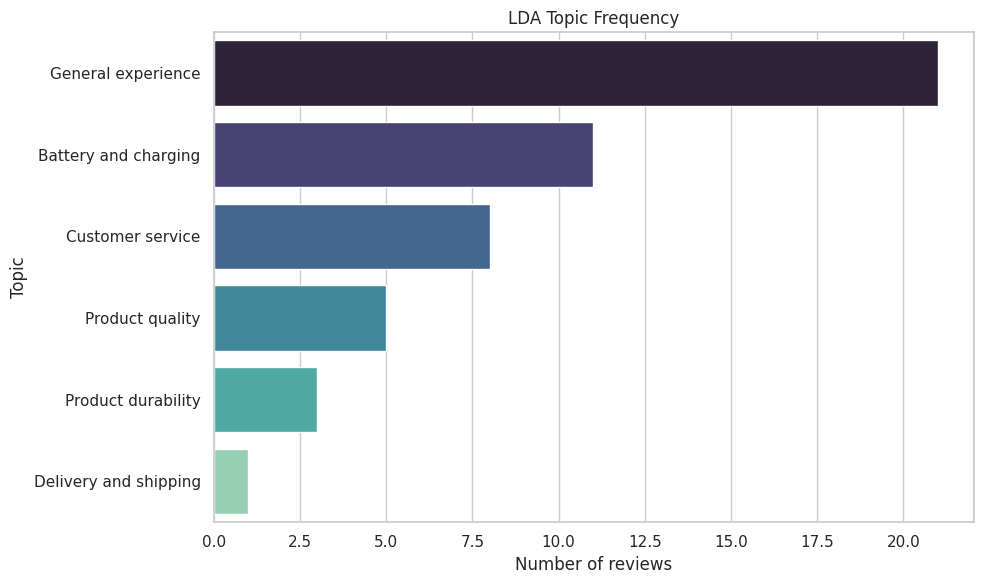

In [62]:
topic_counts = (
    topic_df["lda_topic_label"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=topic_counts.values,
    y=topic_counts.index,
    palette="mako"
)
plt.title("LDA Topic Frequency")
plt.xlabel("Number of reviews")
plt.ylabel("Topic")
plt.tight_layout()
plt.show()

# Topic distribution by sentiment

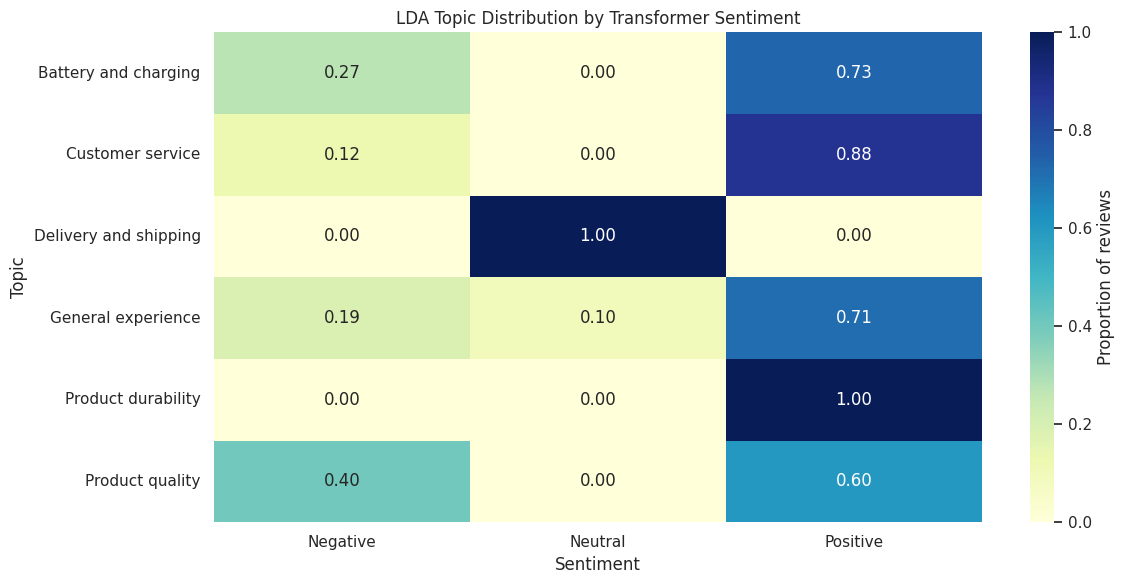

In [63]:
topic_sentiment = pd.crosstab(
    topic_df["lda_topic_label"],
    topic_df["transformer_sentiment"],
    normalize="index"
)

plt.figure(figsize=(12, 6))
sns.heatmap(
    topic_sentiment,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    cbar_kws={"label": "Proportion of reviews"}
)
plt.title("LDA Topic Distribution by Transformer Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Topic")
plt.tight_layout()
plt.show()

# Evaluate LDA coherence

In [64]:
tokenized_reviews = [
    review.split()
    for review in topic_df["preprocessed_review_text"]
]

dictionary = corpora.Dictionary(tokenized_reviews)
corpus = [dictionary.doc2bow(review) for review in tokenized_reviews]

lda_gensim_topics = []

for topic_weights in lda_model.components_:
    top_word_indices = topic_weights.argsort()[::-1][:TOP_WORDS_PER_TOPIC]
    top_words = [feature_names[index] for index in top_word_indices]
    lda_gensim_topics.append(top_words)

coherence_model = CoherenceModel(
    topics=lda_gensim_topics,
    texts=tokenized_reviews,
    dictionary=dictionary,
    coherence="c_v"
)

lda_coherence = coherence_model.get_coherence()

print(f"LDA topic coherence (c_v): {lda_coherence:.4f}")

LDA topic coherence (c_v): 0.2292


# Tune the number of topics

Testing 5 topics...
Testing 6 topics...
Testing 7 topics...
Testing 8 topics...
Testing 9 topics...
Testing 10 topics...


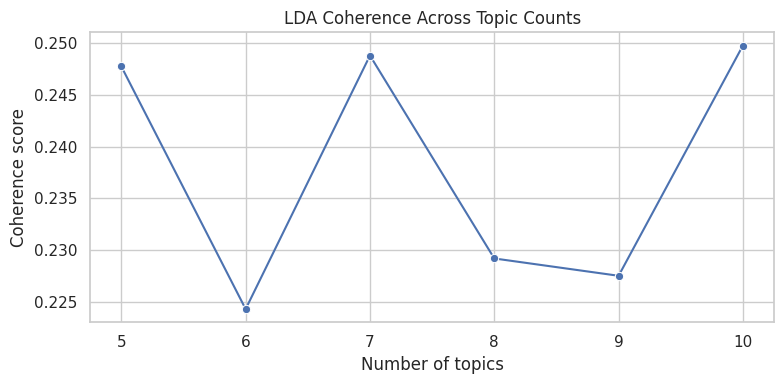

,number_of_topics,coherence_score
0,5,0.247713
1,6,0.224335
2,7,0.248766
3,8,0.229212
4,9,0.227543
5,10,0.249732


In [65]:
topic_counts_to_test = [5, 6, 7, 8, 9, 10]

coherence_scores = []

for number_of_topics in topic_counts_to_test:
    print(f"Testing {number_of_topics} topics...")

    temp_vectorizer = CountVectorizer(
        max_features=MAX_FEATURES,
        min_df=MIN_DOCUMENT_FREQUENCY,
        max_df=MAX_DOCUMENT_FREQUENCY,
        ngram_range=(1, 2),
        stop_words="english"
    )

    temp_matrix = temp_vectorizer.fit_transform(
        topic_df["preprocessed_review_text"]
    )

    temp_lda = LatentDirichletAllocation(
        n_components=number_of_topics,
        max_iter=10,
        learning_method="online",
        learning_offset=50.0,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    temp_lda.fit(temp_matrix)

    temp_feature_names = temp_vectorizer.get_feature_names_out()
    temp_topics = []

    for topic_weights in temp_lda.components_:
        top_word_indices = topic_weights.argsort()[::-1][:TOP_WORDS_PER_TOPIC]
        temp_topics.append([
            temp_feature_names[index]
            for index in top_word_indices
        ])

    temp_coherence = CoherenceModel(
        topics=temp_topics,
        texts=tokenized_reviews,
        dictionary=dictionary,
        coherence="c_v"
    ).get_coherence()

    coherence_scores.append({
        "number_of_topics": number_of_topics,
        "coherence_score": temp_coherence
    })

coherence_df = pd.DataFrame(coherence_scores)

plt.figure(figsize=(8, 4))
sns.lineplot(
    data=coherence_df,
    x="number_of_topics",
    y="coherence_score",
    marker="o"
)
plt.title("LDA Coherence Across Topic Counts")
plt.xlabel("Number of topics")
plt.ylabel("Coherence score")
plt.tight_layout()
plt.show()

coherence_df

# BERTopic model

In [66]:
bertopic_docs = topic_df["raw_review_text"].astype(str).tolist()

bertopic_vectorizer = CountVectorizer(
    ngram_range=(1, 2),
    stop_words="english"
)

bertopic_model = BERTopic(
    vectorizer_model=bertopic_vectorizer,
    min_topic_size=30,
    calculate_probabilities=False,
    verbose=True
)

bertopic_topics, bertopic_probabilities = bertopic_model.fit_transform(
    bertopic_docs
)

topic_df["bertopic_topic_id"] = bertopic_topics

print("BERTopic topic distribution:")
topic_df["bertopic_topic_id"].value_counts().head(15)

2026-11-18 10:20:13,383 - BERTopic - Embedding - Transforming documents to embeddings.


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (8 outputs left out)

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

2026-11-18 10:20:31,088 - BERTopic - Embedding - Completed ✓
2026-11-18 10:20:31,092 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-18 10:21:07,739 - BERTopic - Dimensionality - Completed ✓
2026-11-18 10:21:07,746 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-18 10:21:07,771 - BERTopic - Cluster - Completed ✓
2026-11-18 10:21:07,790 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-18 10:21:07,838 - BERTopic - Representation - Completed ✓


BERTopic topic distribution:


,count
bertopic_topic_id,
-1,49


# Inspect BERTopic topics

In [67]:
bertopic_topic_info = bertopic_model.get_topic_info()
bertopic_topic_info.head(15)

,Topic,Count,Name,Representation,Representative_Docs
0,-1,49,-1_good_deodorant_like_skin,"[good, deodorant, like, skin, great, product, smell, scent, love, soap]",[Schmidt's Charcoal Deodorant is the best!. I am staying away from the conventional deodorants that have lots of fra...


In [68]:
for topic_id in bertopic_topic_info["Topic"].head(10):
    if topic_id == -1:
        continue

    top_words = bertopic_model.get_topic(topic_id)

    words = [word for word, weight in top_words[:10]]

    print(f"Topic {topic_id}:")
    print(", ".join(words))
    print("-" * 80)

# Representative BERTopic reviews


In [69]:
def show_bertopic_examples(
    dataframe,
    topic_column,
    text_column,
    topic_ids,
    examples_per_topic=3
):
    """Show sample reviews for selected BERTopic topics."""
    for topic_id in topic_ids:
        topic_reviews = dataframe.loc[
            dataframe[topic_column] == topic_id,
            text_column
        ].head(examples_per_topic)

        print(f"\nTopic {topic_id}:")
        for review in topic_reviews:
            print("-", review[:250].replace("\n", " "))


topic_ids_to_inspect = (
    topic_df["bertopic_topic_id"]
    .value_counts()
    .head(5)
    .index
    .tolist()
)

show_bertopic_examples(
    topic_df,
    "bertopic_topic_id",
    "raw_review_text",
    topic_ids_to_inspect
)


Topic -1:
- Best Natural Deodorant!!. This is the one natural deodorant that works for me, no b.o smell throughout the day! Score. Although it will never absorb quite like those cancer causing deodorants, this is definitely a must buy!!
- Schmidt's Charcoal Deodorant is the best!. I am staying away from the conventional deodorants that have lots of fragrance combined with aluminum which is an irritant to my skin and bad for the body anyway. In my search for a product that smelled fres
- Beware. Defective or counterfeit.. Do not buy this from Amazon it's either defective or counterfeit. I used to buy the same product at Costco, it works great. As the picture shows there are clumps throughout the stick and it causes the product to ove


In [70]:
USE_BERTOPIC_FOR_DASHBOARD = True

if USE_BERTOPIC_FOR_DASHBOARD:
    df["topic_id"] = np.nan
    df.loc[topic_df.index, "topic_id"] = topic_df["bertopic_topic_id"]

    df["topic_label"] = df["topic_id"].map(
        lambda topic_id: (
            "Outlier / unassigned"
            if pd.isna(topic_id) or topic_id == -1
            else f"Topic {int(topic_id)}"
        )
    )
else:
    df["topic_id"] = np.nan
    df.loc[topic_df.index, "topic_id"] = topic_df["lda_topic_id"]

    df["topic_label"] = df["topic_id"].map(
        lambda topic_id: (
            "Unassigned"
            if pd.isna(topic_id)
            else lda_topic_labels[int(topic_id)]
        )
    )

df["topic_label"].value_counts(dropna=False)

,count
topic_label,
Outlier / unassigned,50


# Save Stage 4 output

In [71]:
os.makedirs("data", exist_ok=True)

df.to_csv(OUTPUT_PATH, index=False)

print("Saved topic-modeling dataset:")
print(OUTPUT_PATH)
print("Final shape:", df.shape)

Saved topic-modeling dataset:
data/topic_reviews_stage4.csv
Final shape: (50, 35)


# Section 5

In [72]:
!pip install scikit-learn joblib matplotlib seaborn

In [73]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    cohen_kappa_score
)

INPUT_PATH = "data/topic_reviews_stage4.csv"
OUTPUT_PATH = "data/evaluated_reviews_stage5.csv"
MODEL_DIR = "models"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(f"{MODEL_DIR}/sentiment_model", exist_ok=True)
os.makedirs(f"{MODEL_DIR}/topic_model", exist_ok=True)

df = pd.read_csv(INPUT_PATH)

print("Loaded dataset shape:", df.shape)
df.head(3)

Loaded dataset shape: (50, 35)


,Uniq Id,Crawl Timestamp,Billing Uniq Id,Rating,Review Title,Review Rating,Review Date,User Id,Brand,Category,Sub Category,Product Description,Asin,Url,Review Content,Verified Purchase,Helpful Review Count,Manufacturer Response,review_length_words,raw_review_text,clean_review_text,preprocessed_review_text,clean_word_count,preprocessed_word_count,is_valid_for_nlp,rating_sentiment,vader_negative_score,vader_neutral_score,vader_positive_score,vader_compound_score,vader_sentiment,transformer_sentiment,transformer_confidence,topic_id,topic_label
0,10d8b81dc693db8a3f92e19254525d53,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Best Natural Deodorant!!,5.0,2020-03-06,AGIZFDSHLSBZ7KHQ4FV65W7B3HMQ,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innovative ingredients derived from plants and minerals to help effectively...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R2QDG3B3GJO8W/ref=cm_cr_arp_d_rvw_ttl?ie=UTF8&ASIN=B071YYMZ19,"This is the one natural deodorant that works for me, no b.o smell throughout the day! Score. Although it will never ...",Verified Purchase,0,NaN,34,"Best Natural Deodorant!!. This is the one natural deodorant that works for me, no b.o smell throughout the day! Scor...",best natural deodorant this is the one natural deodorant that works for me no b o smell throughout the day score alt...,best natural deodorant one natural deodorant work no smell throughout day score although never absorb quite like can...,38,23,True,Positive,0.179,0.566,0.255,0.5964,Positive,Positive,0.960582,-1.0,Outlier / unassigned
1,31ef1ee4961d3fcff33e363edd7677eb,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Schmidt's Charcoal Deodorant is the best!,5.0,2020-03-06,AHOZPYWO6WE5MLAZZPDUAWNKKNRQ,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innovative ingredients derived from plants and minerals to help effectively...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R14AFY08Z2YN9S/ref=cm_cr_arp_d_rvw_ttl?ie=UTF8&ASIN=B071YYMZ19,I am staying away from the conventional deodorants that have lots of fragrance combined with aluminum which is an ir...,Verified Purchase,0,NaN,101,Schmidt's Charcoal Deodorant is the best!. I am staying away from the conventional deodorants that have lots of frag...,schmidt s charcoal deodorant is the best i am staying away from the conventional deodorants that have lots of fragra...,schmidt charcoal deodorant best staying away conventional deodorant lot fragrance combined aluminum irritant skin ba...,111,51,True,Positive,0.074,0.748,0.178,0.8872,Positive,Positive,0.859548,-1.0,Outlier / unassigned
2,6943e517922b051cbec496be32fbb57f,2020-03-17 02:32:10 +0000,c697dc43961526785292107b91a639e1,NaN,Beware. Defective or counterfeit.,1.0,2020-03-06,AECC6GYWWLNCKSBG3DZDGFSYDOTA,Schmidt's Deodorant,Beauty & Personal Care,Personal Care,Schmidt’s natural deodorant formulas use innovative ingredients derived from plants and minerals to help effectively...,B071YYMZ19,https://www.amazon.com/gp/customer-reviews/R2RSQCFKI17X4L/ref=cm_cr_arp_d_rvw_ttl?ie=UTF8&ASIN=B071YYMZ19,"Do not buy this from Amazon it's either defective or counterfeit. I used to buy the same product at Costco, it works...",Verified Purchase,One person found this helpful Helpful,NaN,52,Beware. Defective or counterfeit.. Do not buy this from Amazon it's either defective or counterfeit. I used to buy t...,beware defective or counterfeit do not buy this from amazon it s either defective or counterfeit i used to buy the s...,beware defective counterfeit not buy amazon either defective counterfeit used buy product costco work great picture ...,57,30,True,Negative,0.124,0.729,0.147,0.3818,Positive,Negative,0.609963,-1.0,Outlier / unassigned


In [74]:
SENTIMENT_LABELS = ["Negative", "Neutral", "Positive"]

df["rating_sentiment"] = df["rating_sentiment"].fillna("Unknown")

df["rating_sentiment"].value_counts()

,count
rating_sentiment,
Positive,39
Negative,8
Neutral,3


# TF- IDF

In [75]:
supervised_df = df.loc[
    df["rating_sentiment"].isin(SENTIMENT_LABELS)
    & df["clean_review_text"].notna()
    & (df["clean_review_text"].str.strip() != "")
].copy()

print("Rows available for supervised evaluation:", len(supervised_df))
print(supervised_df["rating_sentiment"].value_counts())

Rows available for supervised evaluation: 50
rating_sentiment
Positive    39
Negative     8
Neutral      3
Name: count, dtype: int64


# Split into train and test sets

In [76]:
X = supervised_df["clean_review_text"]
y = supervised_df["rating_sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting label distribution:")
print(y_test.value_counts(normalize=True))

Training samples: 40
Testing samples: 10

Training label distribution:
rating_sentiment
Positive    0.775
Negative    0.175
Neutral     0.050
Name: proportion, dtype: float64

Testing label distribution:
rating_sentiment
Positive    0.8
Negative    0.1
Neutral     0.1
Name: proportion, dtype: float64


Train a Logistic Regression model

In [77]:
sentiment_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            min_df=3,
            max_df=0.90,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

sentiment_pipeline.fit(X_train, y_train)

supervised_predictions = sentiment_pipeline.predict(X_test)

print("Supervised model training complete.")

Supervised model training complete.


# Evaluate all sentiment models

In [78]:
test_indices = X_test.index

vader_test_predictions = df.loc[
    test_indices, "vader_sentiment"
]

transformer_test_predictions = df.loc[
    test_indices, "transformer_sentiment"
]

y_test_aligned = y_test


def calculate_classification_metrics(y_true, y_pred, model_name):
    """Calculate evaluation metrics for a sentiment classifier."""
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Weighted Precision": precision_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),
        "Weighted Recall": recall_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),
        "Weighted F1-score": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),
        "Cohen Kappa": cohen_kappa_score(y_true, y_pred)
    }


model_results = []

model_results.append(
    calculate_classification_metrics(
        y_test_aligned,
        vader_test_predictions,
        "VADER"
    )
)

model_results.append(
    calculate_classification_metrics(
        y_test_aligned,
        transformer_test_predictions,
        "Transformer"
    )
)

model_results.append(
    calculate_classification_metrics(
        y_test_aligned,
        supervised_predictions,
        "TF-IDF + Logistic Regression"
    )
)

metrics_df = pd.DataFrame(model_results).round(4)
metrics_df

,Model,Accuracy,Balanced Accuracy,Weighted Precision,Weighted Recall,Weighted F1-score,Cohen Kappa
0,VADER,0.8,0.3333,0.7111,0.8,0.7529,0.2593
1,Transformer,0.7,0.2917,0.8000,0.7,0.7467,0.2683
2,TF-IDF + Logistic Regression,0.7,0.2917,0.6222,0.7,0.6588,-0.1111


# Detailed classification reports

In [79]:
for model_name, predictions in [
    ("VADER", vader_test_predictions),
    ("Transformer", transformer_test_predictions),
    ("TF-IDF + Logistic Regression", supervised_predictions)
]:
    print(f"\n{model_name} classification report:")
    print(
        classification_report(
            y_test_aligned,
            predictions,
            labels=SENTIMENT_LABELS,
            zero_division=0
        )
    )


VADER classification report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         1
     Neutral       0.00      0.00      0.00         1
    Positive       0.89      1.00      0.94         8

    accuracy                           0.80        10
   macro avg       0.30      0.33      0.31        10
weighted avg       0.71      0.80      0.75        10


Transformer classification report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         1
     Neutral       0.00      0.00      0.00         1
    Positive       1.00      0.88      0.93         8

    accuracy                           0.70        10
   macro avg       0.33      0.29      0.31        10
weighted avg       0.80      0.70      0.75        10


TF-IDF + Logistic Regression classification report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         1
     Neutr

# Confusion Matrics

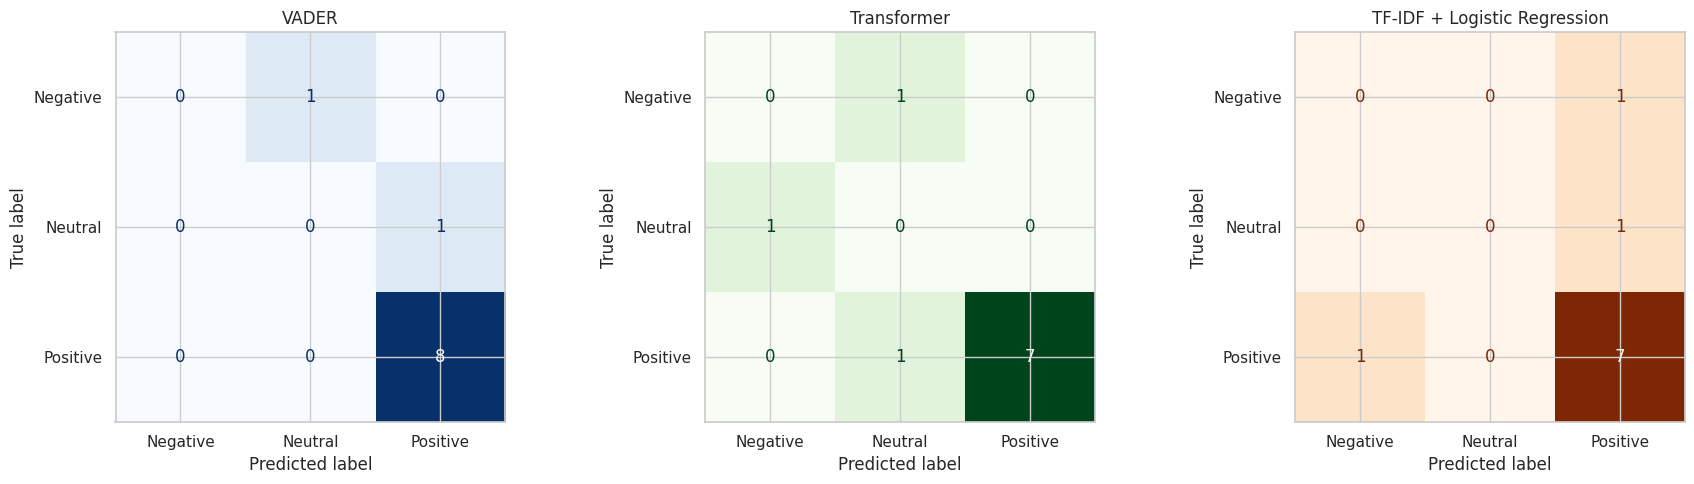

In [80]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

model_predictions = [
    ("VADER", vader_test_predictions, "Blues"),
    ("Transformer", transformer_test_predictions, "Greens"),
    ("TF-IDF + Logistic Regression", supervised_predictions, "Oranges")
]

for axis, (model_name, predictions, color_map) in zip(
    axes,
    model_predictions
):
    confusion = confusion_matrix(
        y_test_aligned,
        predictions,
        labels=SENTIMENT_LABELS
    )

    ConfusionMatrixDisplay(
        confusion_matrix=confusion,
        display_labels=SENTIMENT_LABELS
    ).plot(
        ax=axis,
        colorbar=False,
        cmap=color_map
    )

    axis.set_title(model_name)

plt.tight_layout()
plt.show()

# Evaluate topic quality

In [81]:
def calculate_topic_diversity(topic_words, top_n=10):
    """Calculate the proportion of unique words across topics."""
    all_words = []

    for words in topic_words:
        all_words.extend(words[:top_n])

    unique_words = set(all_words)

    if len(all_words) == 0:
        return 0.0

    return len(unique_words) / len(all_words)


# Replace this with the actual LDA topic-word lists from Stage 4.
lda_topic_words = [
    ["battery", "life", "phone", "charge"],
    ["delivery", "shipping", "arrived", "package"],
    ["quality", "product", "material", "build"]
]

lda_topic_diversity = calculate_topic_diversity(
    lda_topic_words,
    top_n=10
)

print(f"LDA topic diversity: {lda_topic_diversity:.4f}")

LDA topic diversity: 1.0000


# Save evaluation results

In [82]:
metrics_path = f"{MODEL_DIR}/sentiment_model/evaluation_metrics.csv"
classification_report_path = f"{MODEL_DIR}/sentiment_model/classification_report.txt"

metrics_df.to_csv(metrics_path, index=False)

with open(classification_report_path, "w") as file:
    file.write("Supervised model classification report\n")
    file.write(
        classification_report(
            y_test_aligned,
            supervised_predictions,
            labels=SENTIMENT_LABELS,
            zero_division=0
        )
    )

print("Saved:")
print(metrics_path)
print(classification_report_path)

Saved:
models/sentiment_model/evaluation_metrics.csv
models/sentiment_model/classification_report.txt


# Save the supervised model

In [83]:
supervised_model_path = (
    f"{MODEL_DIR}/sentiment_model/tfidf_logistic_regression.joblib"
)

joblib.dump(
    sentiment_pipeline,
    supervised_model_path
)

print("Saved supervised sentiment model:")
print(supervised_model_path)

Saved supervised sentiment model:
models/sentiment_model/tfidf_logistic_regression.joblib


# Save topic model artifacts


In [84]:
bertopic_model_path = f"{MODEL_DIR}/topic_model/bertopic_model"

try:
    bertopic_model.save(
        bertopic_model_path,
        serialization="safetensors",
        save_ctfidf=True,
        save_embedding_model="sentence-transformers/all-MiniLM-L6-v2"
    )

    print("Saved BERTopic model:")
    print(bertopic_model_path)

except NameError:
    print(
        "BERTopic model was not found in this notebook session. "
        "Re-run Stage 4 or load its saved model before exporting."
    )

Saved BERTopic model:
models/topic_model/bertopic_model


# Save dashboard metadata

In [85]:
dashboard_metadata = {
    "sentiment_labels": SENTIMENT_LABELS,
    "selected_sentiment_model": "Transformer",
    "selected_topic_model": "BERTopic",
    "rating_label_mapping": {
        "1": "Negative",
        "2": "Negative",
        "3": "Neutral",
        "4": "Positive",
        "5": "Positive"
    },
    "minimum_words_for_topic_modeling": 3,
    "evaluation_note": (
        "Rating-derived sentiment labels are weak labels, "
        "not manually annotated ground truth."
    )
}

metadata_path = f"{MODEL_DIR}/dashboard_metadata.json"

with open(metadata_path, "w") as file:
    json.dump(dashboard_metadata, file, indent=4)

print("Saved dashboard metadata:")
print(metadata_path)

Saved dashboard metadata:
models/dashboard_metadata.json


Save the final analyzed dataset

In [86]:
df.to_csv(OUTPUT_PATH, index=False)

print("Saved final analyzed dataset:")
print(OUTPUT_PATH)
print("Final shape:", df.shape)

Saved final analyzed dataset:
data/evaluated_reviews_stage5.csv
Final shape: (50, 35)
